# ДЗ 1. Бэггинг и бустинг

Гаврилина Алёна Дмитриевна

Датасет: creditcardfraud (0 — нет мошенничества, 1 — есть).

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RS = 42

In [2]:
df = pd.read_csv('../hometasks/creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Данные
Классы сильно несбалансированы, поэтому одной accuracy мало — смотрим precision, recall, F1 и PR-AUC.

In [3]:
print(df.shape, 'пропусков:', df.isna().sum().sum())
print(df['Class'].value_counts())
print(df['Class'].value_counts(normalize=True).round(5))

(284807, 31) пропусков: 0
Class
0    284315
1       492
Name: count, dtype: int64
Class
0    0.99827
1    0.00173
Name: proportion, dtype: float64


In [4]:
X = df.drop(columns='Class')
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RS)
print(X_train.shape, X_test.shape, y_train.mean().round(5), y_test.mean().round(5))

(213605, 30) (71202, 30) 0.00173 0.00173


## 2. Подбор параметров с помощью GridSearchCV
Датасет большой, поэтому поиск по сетке делаем на стратифицированной подвыборке train (60 000 строк), а финальные модели обучаем на всём train. Метрика для выбора — `average_precision` (PR-AUC), так как она подходит для сильно несбалансированных классов.

In [5]:
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=60000, stratify=y_train, random_state=RS)
print(X_sub.shape, y_sub.sum(), 'мошеннических операций в подвыборке')
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)

(60000, 30) 104 мошеннических операций в подвыборке


### 2.1 Бэггинг (над деревьями решений)

In [6]:
bag_grid = {
    'n_estimators': [10, 30],
    'max_samples': [0.5, 1.0],
    'max_features': [0.5, 1.0],
    'estimator__max_depth': [None, 10],
}
bag_gs = GridSearchCV(
    BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RS), random_state=RS),
    bag_grid, scoring='average_precision', cv=cv, n_jobs=-1, verbose=1)
t = time.time(); bag_gs.fit(X_sub, y_sub); print('время, c:', round(time.time()-t))
print('Лучшие параметры:', bag_gs.best_params_)
print('Лучший CV PR-AUC:', round(bag_gs.best_score_, 4))

Fitting 3 folds for each of 16 candidates, totalling 48 fits


время, c: 302
Лучшие параметры: {'estimator__max_depth': 10, 'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 30}
Лучший CV PR-AUC: 0.7879


In [7]:
pd.DataFrame(bag_gs.cv_results_)[['params','mean_test_score','std_test_score','rank_test_score']].sort_values('rank_test_score').head(10)

,params,mean_test_score,std_test_score,rank_test_score
9,"{'estimator__max_depth': 10, 'max_features': 0...",0.787907,0.015817,1
15,"{'estimator__max_depth': 10, 'max_features': 1...",0.781715,0.018657,2
1,"{'estimator__max_depth': None, 'max_features':...",0.776904,0.010562,3
11,"{'estimator__max_depth': 10, 'max_features': 0...",0.775764,0.017195,4
7,"{'estimator__max_depth': None, 'max_features':...",0.772549,0.017562,5
3,"{'estimator__max_depth': None, 'max_features':...",0.759418,0.013055,6
13,"{'estimator__max_depth': 10, 'max_features': 1...",0.756393,0.027863,7
5,"{'estimator__max_depth': None, 'max_features':...",0.753109,0.029509,8
14,"{'estimator__max_depth': 10, 'max_features': 1...",0.750830,0.024354,9
8,"{'estimator__max_depth': 10, 'max_features': 0...",0.748570,0.009063,10


### 2.2 Бустинг (GradientBoosting)

In [8]:
boost_grid = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 5],
}
boost_gs = GridSearchCV(
    GradientBoostingClassifier(max_features='sqrt', random_state=RS),
    boost_grid, scoring='average_precision', cv=cv, n_jobs=-1, verbose=1)
t = time.time(); boost_gs.fit(X_sub, y_sub); print('время, c:', round(time.time()-t))
print('Лучшие параметры:', boost_gs.best_params_)
print('Лучший CV PR-AUC:', round(boost_gs.best_score_, 4))

Fitting 3 folds for each of 8 candidates, totalling 24 fits


время, c: 281
Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}
Лучший CV PR-AUC: 0.6352


In [9]:
pd.DataFrame(boost_gs.cv_results_)[['params','mean_test_score','std_test_score','rank_test_score']].sort_values('rank_test_score').head(10)

,params,mean_test_score,std_test_score,rank_test_score
3,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.635192,0.035642,1
2,"{'learning_rate': 0.05, 'max_depth': 5, 'n_est...",0.611436,0.047825,2
6,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.557312,0.030938,3
1,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.502316,0.111428,4
0,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",0.492185,0.109426,5
7,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.456580,0.141095,6
4,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.445797,0.026598,7
5,"{'learning_rate': 0.1, 'max_depth': 3, 'n_esti...",0.408751,0.052874,8


## 3. Обучение моделей с лучшими параметрами на всём train

In [10]:
best_bag = bag_gs.best_params_
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(max_depth=best_bag['estimator__max_depth'], random_state=RS),
    n_estimators=best_bag['n_estimators'], max_samples=best_bag['max_samples'],
    max_features=best_bag['max_features'], random_state=RS, n_jobs=-1)
t = time.time(); bagging.fit(X_train, y_train); print('Bagging, c:', round(time.time()-t))

boosting = GradientBoostingClassifier(**boost_gs.best_params_, max_features='sqrt', random_state=RS)
t = time.time(); boosting.fit(X_train, y_train); print('Boosting, c:', round(time.time()-t))

Bagging, c: 45


Boosting, c: 121


## 4. Сравнение моделей на тестовой выборке

In [11]:
models = {'Bagging': bagging, 'Boosting': boosting}
rows, preds = [], {}
for name, m in models.items():
    pred = m.predict(X_test); proba = m.predict_proba(X_test)[:, 1]
    preds[name] = (pred, proba)
    rows.append({'model': name,
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred, zero_division=0),
                 'recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba),
                 'PR-AUC': average_precision_score(y_test, proba)})
res = pd.DataFrame(rows).set_index('model').round(4)
res

,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,
Bagging,0.9995,0.9592,0.7642,0.8507,0.9705,0.8330
Boosting,0.9988,0.7065,0.5285,0.6047,0.6749,0.4626


In [12]:
for name, (pred, proba) in preds.items():
    print('=====', name)
    print(classification_report(y_test, pred, digits=4))

===== Bagging
              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     71079
           1     0.9592    0.7642    0.8507       123

    accuracy                         0.9995     71202
   macro avg     0.9794    0.8821    0.9252     71202
weighted avg     0.9995    0.9995    0.9995     71202

===== Boosting
              precision    recall  f1-score   support

           0     0.9992    0.9996    0.9994     71079
           1     0.7065    0.5285    0.6047       123

    accuracy                         0.9988     71202
   macro avg     0.8529    0.7640    0.8020     71202
weighted avg     0.9987    0.9988    0.9987     71202



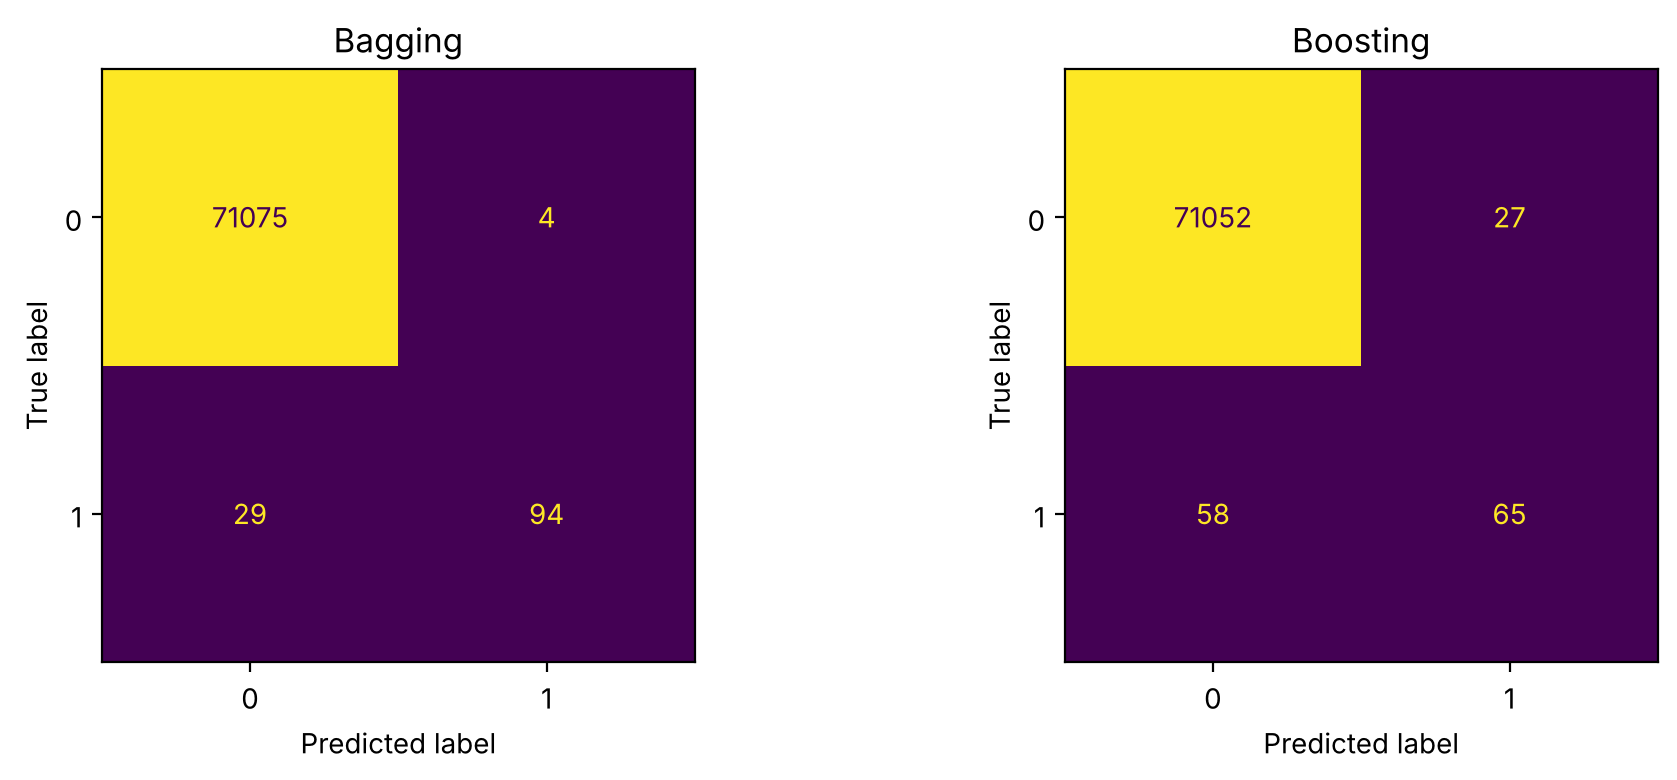

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (pred, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

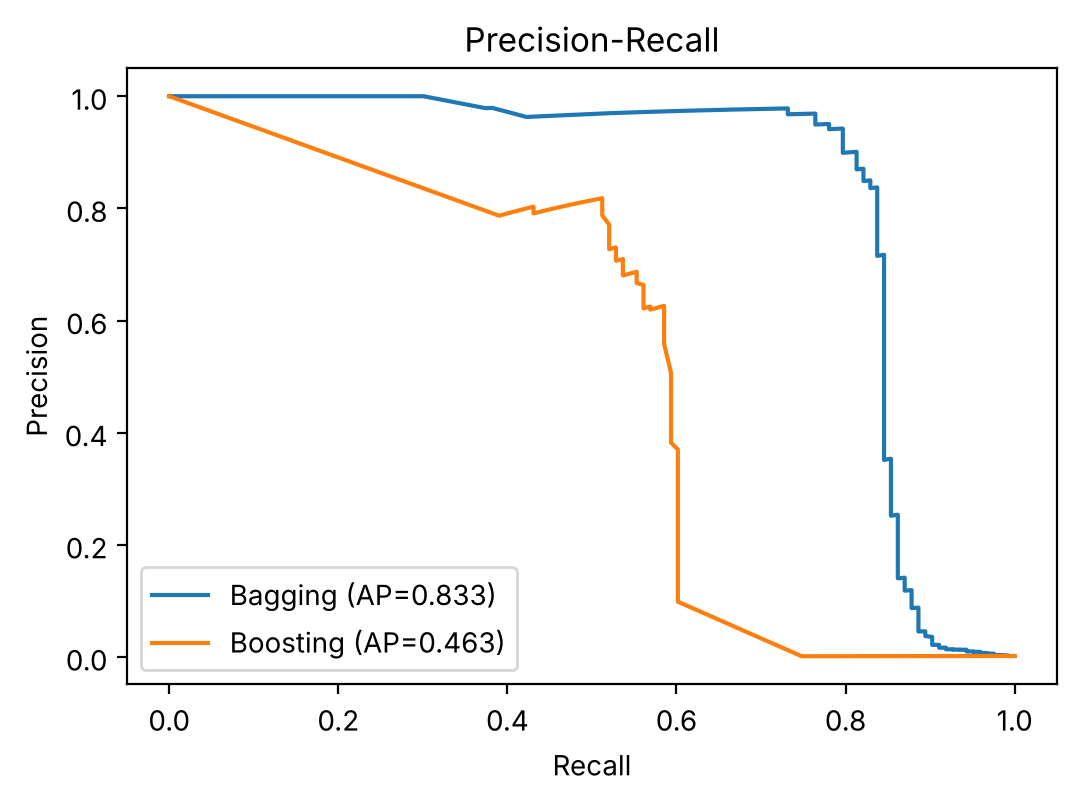

In [14]:
from sklearn.metrics import precision_recall_curve
plt.figure(figsize=(6, 4))
for name, (_, proba) in preds.items():
    p, r, _ = precision_recall_curve(y_test, proba)
    plt.plot(r, p, label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend(); plt.title('Precision-Recall'); plt.show()

## 5. Выводы

**Лучшие параметры (GridSearchCV, метрика PR-AUC, 3-fold CV на подвыборке 60 000 строк):**
- Бэггинг: `n_estimators=30`, `max_samples=0.5`, `max_features=0.5`, `max_depth=10` (CV PR-AUC ≈ 0.788).
- Бустинг: `n_estimators=200`, `learning_rate=0.05`, `max_depth=5`, `max_features='sqrt'` (CV PR-AUC ≈ 0.635).

**Сравнение на тесте:** бэггинг заметно лучше бустинга. У бэггинга precision 0.96, recall 0.76, F1 0.85, PR-AUC 0.83; у бустинга precision 0.71, recall 0.53, F1 0.60, PR-AUC 0.46. Accuracy почти одинаковая (0.9995 и 0.9988) и ничего не показывает из-за дисбаланса классов (мошенничество — 0.17%), поэтому ориентируемся на F1 и PR-AUC.

**Почему так:** бэггинг усредняет глубокие деревья, обученные на разных подвыборках, и снижает дисперсию; на данных с очень малым числом положительных примеров это работает устойчиво. Градиентный бустинг последовательно подстраивается под редкий класс, более чувствителен к шуму и гиперпараметрам (разброс CV-оценок между комбинациями большой: std до 0.14), а сетка была небольшой и ограничена вычислительными ресурсами. ROC-AUC бустинга (≈ 0.67) низкий: часть мошеннических операций получает очень малые вероятности, поэтому для него метрики по порогу и PR-AUC информативнее.

**Ограничения:** подбор параметров делался на подвыборке с ~100 мошенническими операциями, сетки небольшие, баланс классов не корректировался (SMOTE, class_weight, подбор порога могли бы улучшить recall). Для бустинга разумно попробовать более широкую сетку или XGBoost/LightGBM.